<a href="https://colab.research.google.com/github/rafalubis/Addition_Subtraction/blob/main/PCD_Kematangan_Pisang_Minggu2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Kematangan Pisang: HSV + Segmentasi + Morfologi + KNN
**Pengolahan Citra Digital 2026 | Progress Minggu 2**

Notebook ini mencakup: indeks dataset, EDA, cek duplikat (exact dan near-duplicate), split validasi bebas kebocoran, pipeline prapemrosesan dan segmentasi, ekstraksi fitur ke CSV, serta KNN awal di data **validasi**.

**Struktur dataset yang diharapkan:**
```
DATA_DIR/
  train/<nama_kelas>/*.jpg
  test/<nama_kelas>/*.jpg
```
Data **test tidak dipakai** untuk memilih apa pun. Evaluasi test ada di sel terakhir dan hanya dijalankan sekali di akhir proyek.

## 0. Setup dan konfigurasi

In [5]:
# Di Colab, hapus tanda # pada baris berikut (jika perlu):
# %pip install -q opencv-python-headless scikit-learn pandas matplotlib
# from google.colab import drive; drive.mount('/content/drive')

import os, hashlib, warnings, random
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
warnings.filterwarnings("ignore")

# ===================== KONFIGURASI (ubah di sini) =====================
DATA_DIR  = Path(os.environ.get("DATA_DIR", "dataset"))   # folder berisi train/ dan test/
OUT_DIR   = Path(os.environ.get("OUT_DIR", "outputs"))
SEED      = 42
IMG_SIZE  = 224

# Urutan kelas dari paling mentah ke paling matang, SESUAI nama folder dataset.
# Contoh: ["unripe", "semiripe", "ripe", "overripe"]. Jika None, urutan alfabet dipakai
# dan analisis ordinal dilewati.
CLASS_ORDER = None

# Near-duplicate (dHash): jarak Hamming maksimum (dari 64 bit) yang dianggap near-duplicate.
HAMMING_T = 4

# Segmentasi
SEG_METHOD = "bg"          # "bg" = kebalikan latar (S rendah & V tinggi); "range" = rentang warna pisang
BG_S_MAX, BG_V_MIN = 40, 190   # latar = S <= BG_S_MAX dan V >= BG_V_MIN  (KALIBRASI di bagian 4)
KERNEL = 5                 # ukuran kernel opening/closing
MIN_PIXELS = 50            # mask lebih kecil dari ini dianggap gagal
SEG_OK_MIN, SEG_OK_MAX = 0.05, 0.95   # rasio luas mask yang dianggap wajar (kriteria "segmentasi gagal")

# Rentang HSV OpenCV (H: 0-179, S/V: 0-255). Ini NILAI AWAL, kalibrasi dengan data latih di bagian 4.
HSV_RANGES = {
    "hijau":   [(36, 40, 40),  (85, 255, 255)],
    "kuning":  [(20, 60, 80),  (35, 255, 255)],
    "cokelat": [(5, 50, 20),   (19, 255, 190)],
}

random.seed(SEED); np.random.seed(SEED)
(OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)
print("DATA_DIR:", DATA_DIR.resolve(), "| OpenCV", cv2.__version__)

DATA_DIR: /content/dataset | OpenCV 5.0.0


## 1. Indeks dataset

In [6]:
from pathlib import Path
import pandas as pd
import zipfile

with zipfile.ZipFile('Banana Ripeness Image.zip', 'r') as zip_ref:
    zip_ref.extractall('dataset_pisang')

DATA_DIR = Path('dataset_pisang')

EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
rows = []

for split in ["train", "test"]:
    split_dir = DATA_DIR / split
    if split_dir.exists():
        for cdir in sorted(split_dir.iterdir()):
            if cdir.is_dir():
                for p in sorted(cdir.iterdir()):
                    if p.suffix.lower() in EXTS:
                        rows.append(dict(path=str(p), nama_file=p.name, split=split, label=cdir.name))

df = pd.DataFrame(rows)
assert len(df) > 0, "Tidak ada gambar ditemukan. Periksa DATA_DIR dan struktur folder."

found = sorted(df.label.unique())
if CLASS_ORDER is None:
    CLASS_ORDER = found
    ORDINAL_OK = False
    print("PERINGATAN: CLASS_ORDER belum diatur. Folder kelas terdeteksi:", found)
    print("Atur CLASS_ORDER dari mentah ke terlalu matang agar analisis ordinal berjalan.")
else:
    assert set(CLASS_ORDER) == set(found), f"CLASS_ORDER tidak cocok dengan folder: {found}"
    ORDINAL_OK = True

RANK = {c: i for i, c in enumerate(CLASS_ORDER)}

print("\nDistribusi Dataset:")
print(pd.crosstab(df.label, df.split).reindex(CLASS_ORDER))

PERINGATAN: CLASS_ORDER belum diatur. Folder kelas terdeteksi: ['matang', 'mentah', 'setengah-matang', 'terlalu-matang']
Atur CLASS_ORDER dari mentah ke terlalu matang agar analisis ordinal berjalan.

Distribusi Dataset:
split            test  train
label                       
matang             59    235
mentah             99    392
setengah-matang   122    484
terlalu-matang     95    379


## 2. EDA: sampel tiap kelas

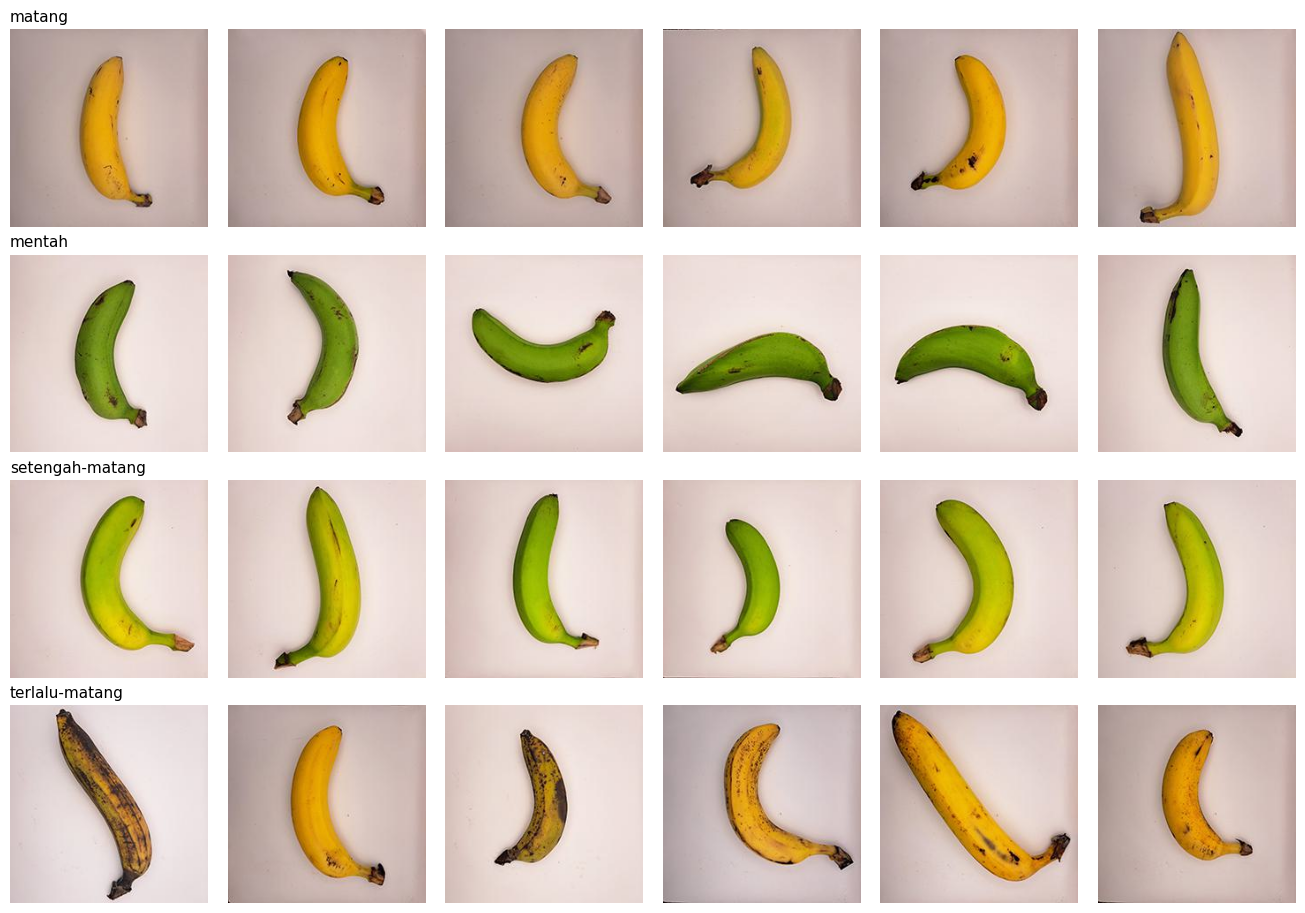

In [7]:
def read_bgr(path, size=IMG_SIZE):
    img = cv2.imread(str(path))
    if img is None:
        raise FileNotFoundError(path)
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)

def show_samples(df_, n=6):
    fig, axes = plt.subplots(len(CLASS_ORDER), n, figsize=(2.2*n, 2.3*len(CLASS_ORDER)))
    axes = np.atleast_2d(axes)
    for i, c in enumerate(CLASS_ORDER):
        sub = df_[df_.label == c].sample(min(n, (df_.label == c).sum()), random_state=SEED)
        for j in range(n):
            ax = axes[i, j]; ax.axis("off")
            if j < len(sub):
                ax.imshow(cv2.cvtColor(read_bgr(sub.iloc[j].path), cv2.COLOR_BGR2RGB))
            if j == 0:
                ax.set_title(c, loc="left", fontsize=11)
    plt.tight_layout(); plt.savefig(OUT_DIR/"figures/eda_samples.png", dpi=130); plt.show()

show_samples(df[df.split == "train"])
# Catat ciri visual tiap kelas dari gambar di atas (warna dominan, bercak cokelat) untuk slide dan laporan.

## 3. Kualitas data: duplikat dan pembagian validasi
Dua lapis pemeriksaan:
1. **Exact duplicate** lewat hash MD5 (byte identik).
2. **Near-duplicate** lewat perceptual hash (dHash) yang diuji terhadap 8 orientasi (rotasi/flip), sehingga foto yang sama setelah diputar tetap tertangkap.

Hasil near-duplicate dipakai untuk membuat split validasi **per klaster** (`StratifiedGroupKFold`), supaya citra mirip tidak terpisah antara train dan validasi. Metode ini tidak bisa memastikan foto buah yang sama dari sudut berbeda; itu tetap keterbatasan.

In [8]:
# --- 3a. Exact duplicate (MD5) ---
df["md5"] = [hashlib.md5(open(p, "rb").read()).hexdigest() for p in df.path]
dup_exact = df[df.duplicated("md5", keep=False)].sort_values("md5")
print(f"Exact duplicate: {len(dup_exact)} citra terlibat dalam {dup_exact.md5.nunique()} grup")
if len(dup_exact):
    cross = dup_exact.groupby("md5").split.nunique().gt(1).sum()
    print(f"  grup yang melintasi train-test: {cross}")
    display(dup_exact[["nama_file", "split", "label"]].head(20))

Exact duplicate: 0 citra terlibat dalam 0 grup


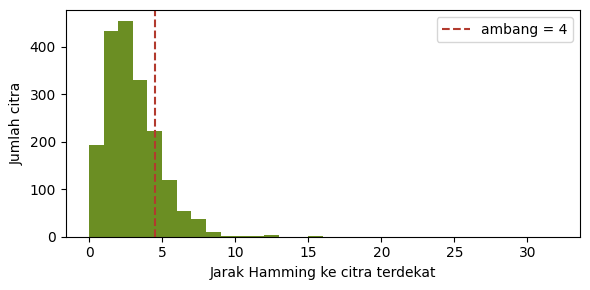

Pasangan near-duplicate (jarak <= 4): 28430
  lintas train-test: 10281
  beda label (indikasi label berisik atau ambang terlalu longgar): 16895


In [9]:
# --- 3b. Near-duplicate (dHash, 8 orientasi) ---
def dihedral(g):
    out = []
    for k in range(4):
        r = np.rot90(g, k)
        out += [r, np.fliplr(r)]
    return out            # 8 variasi

def dhash_bits(g):
    s = cv2.resize(g, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (s[:, 1:] > s[:, :-1]).flatten().astype(np.float32)   # 64 bit

bits = np.zeros((8, len(df), 64), np.float32)
for i, p in enumerate(df.path):
    g = cv2.cvtColor(read_bgr(p), cv2.COLOR_BGR2GRAY)
    for v, gv in enumerate(dihedral(g)):
        bits[v, i] = dhash_bits(np.ascontiguousarray(gv))

O = bits[0]
D = np.full((len(df), len(df)), 64, np.float32)
for v in range(8):
    V = bits[v]
    D = np.minimum(D, O @ (1 - V).T + (1 - O) @ V.T)    # jarak Hamming
np.fill_diagonal(D, 64)

nn = D.min(axis=1)
plt.figure(figsize=(6, 3)); plt.hist(nn, bins=range(0, 33), color="#6B8E23")
plt.axvline(HAMMING_T + 0.5, color="#B23A2E", ls="--", label=f"ambang = {HAMMING_T}")
plt.xlabel("Jarak Hamming ke citra terdekat"); plt.ylabel("Jumlah citra"); plt.legend()
plt.tight_layout(); plt.savefig(OUT_DIR/"figures/near_dup_hist.png", dpi=130); plt.show()

ia, ib = np.where(np.triu(D <= HAMMING_T, 1))
pairs = pd.DataFrame(dict(a=ia, b=ib, dist=D[ia, ib]))
pairs["split_a"] = df.split.values[ia]; pairs["split_b"] = df.split.values[ib]
pairs["label_a"] = df.label.values[ia]; pairs["label_b"] = df.label.values[ib]
pairs["lintas_split"] = pairs.split_a != pairs.split_b
print(f"Pasangan near-duplicate (jarak <= {HAMMING_T}): {len(pairs)}")
print(f"  lintas train-test: {int((pairs.split_a.ne(pairs.split_b)).sum())}")
print(f"  beda label (indikasi label berisik atau ambang terlalu longgar): {int((pairs.label_a != pairs.label_b).sum())}")

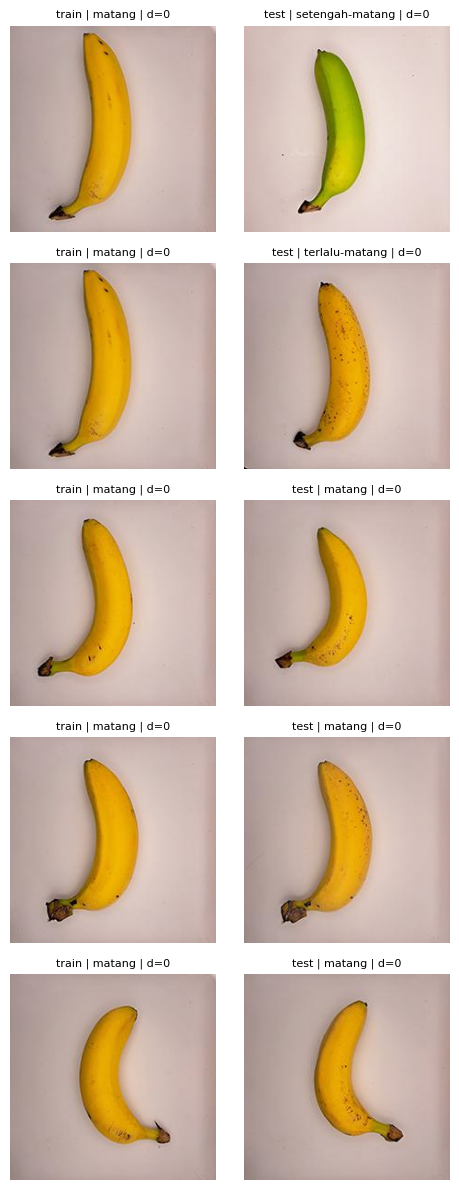

In [10]:
# Lihat contoh pasangan agar ambang bisa dinilai secara visual (lintas-split ditampilkan lebih dulu)
def show_pairs(pairs_, n=5):
    ps = pairs_.sort_values(["lintas_split", "dist"], ascending=[False, True]).head(n)
    if len(ps) == 0:
        print("Tidak ada pasangan pada ambang ini."); return
    fig, axes = plt.subplots(len(ps), 2, figsize=(5, 2.4*len(ps))); axes = np.atleast_2d(axes)
    for r, (_, row) in enumerate(ps.iterrows()):
        for c, idx in enumerate([row.a, row.b]):
            axes[r, c].imshow(cv2.cvtColor(read_bgr(df.path[idx]), cv2.COLOR_BGR2RGB)); axes[r, c].axis("off")
            axes[r, c].set_title(f"{df.split[idx]} | {df.label[idx]} | d={int(row.dist)}", fontsize=8)
    plt.tight_layout(); plt.show()
show_pairs(pairs)

In [11]:
# --- 3c. Klaster near-duplicate dan split validasi per klaster ---
def components(n, pair_idx):
    parent = list(range(n))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for a, b in pair_idx:
        ra, rb = find(a), find(b)
        if ra != rb: parent[rb] = ra
    return np.array([find(i) for i in range(n)])

df["group"] = components(len(df), zip(pairs.a, pairs.b))
sizes = df.groupby("group").size()
print("Ukuran klaster terbesar:", sizes.max(), "| klaster berisi >1 citra:", int((sizes > 1).sum()))
if sizes.max() > 0.05 * len(df):
    print("PERINGATAN: ada klaster sangat besar. Ambang HAMMING_T mungkin terlalu longgar (latar polos membuat citra mirip).")

tr = df[df.split == "train"].reset_index()          # kolom 'index' = indeks asli di df
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
_, val_pos = next(sgkf.split(tr, tr.label, groups=tr.group))
df.loc[tr.loc[val_pos, "index"].values, "split"] = "val"

print(pd.crosstab(df.label, df.split).reindex(CLASS_ORDER)[["train", "val", "test"]])
leak = set(df[df.split == "train"].group) & set(df[df.split == "val"].group)
print("Klaster yang dibagi antara train dan validasi (harus 0):", len(leak))
df[["nama_file", "label", "split", "group", "md5"]].to_csv(OUT_DIR / "split.csv", index=False)

Ukuran klaster terbesar: 1608 | klaster berisi >1 citra: 23
PERINGATAN: ada klaster sangat besar. Ambang HAMMING_T mungkin terlalu longgar (latar polos membuat citra mirip).
split            train  val  test
label                            
matang             216   19    59
mentah             384    8    99
setengah-matang    478    6   122
terlalu-matang     365   14    95
Klaster yang dibagi antara train dan validasi (harus 0): 0


## 4. Prapemrosesan dan segmentasi
Pipeline: resize → Gaussian blur → BGR ke HSV → segmentasi → opening → closing → (komponen terbesar).

Dua metode mask tersedia:
- `bg`: mask = **kebalikan latar** (latar polos terang memiliki S rendah dan V tinggi). Rentang warna pisang tidak dipakai untuk menentukan objek, sehingga bercak cokelat tidak ikut terbuang.
- `range`: mask = gabungan rentang HSV hijau/kuning/cokelat (sesuai usulan awal).

Bagian 4b membandingkan keduanya untuk menjawab: *apakah mask rentang warna kehilangan piksel objek, terutama di kelas terlalu matang?*

In [12]:
def in_range(hsv, name):
    lo, hi = HSV_RANGES[name]
    return cv2.inRange(hsv, np.array(lo, np.uint8), np.array(hi, np.uint8))

def raw_mask(hsv, method):
    if method == "bg":
        bg = (hsv[..., 1] <= BG_S_MAX) & (hsv[..., 2] >= BG_V_MIN)
        return (~bg).astype(np.uint8) * 255
    m = np.zeros(hsv.shape[:2], np.uint8)
    for n in HSV_RANGES:
        m |= in_range(hsv, n)
    return m

def clean_mask(m, keep_largest=True):
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (KERNEL, KERNEL))
    o = cv2.morphologyEx(m, cv2.MORPH_OPEN, k)
    c = cv2.morphologyEx(o, cv2.MORPH_CLOSE, k)
    if not keep_largest:
        return c
    n, lab, stats, _ = cv2.connectedComponentsWithStats((c > 0).astype(np.uint8), connectivity=8)
    if n <= 1:
        return c
    big = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    return ((lab == big) * 255).astype(np.uint8)

def run_pipeline(bgr, method=None):
    method = method or SEG_METHOD
    blur = cv2.GaussianBlur(bgr, (5, 5), 0)
    hsv = cv2.cvtColor(blur, cv2.COLOR_BGR2HSV)
    raw = raw_mask(hsv, method)
    return dict(bgr=bgr, blur=blur, hsv=hsv, raw=raw, mask=clean_mask(raw))

# Uji cepat pada satu citra
o = run_pipeline(read_bgr(df.path[0]))
print({k: v.shape for k, v in o.items()})

{'bgr': (224, 224, 3), 'blur': (224, 224, 3), 'hsv': (224, 224, 3), 'raw': (224, 224), 'mask': (224, 224)}


In [13]:
# --- 4a. Bantuan kalibrasi: sebaran H, S, V piksel objek per kelas (HANYA data latih) ---
def hsv_percentiles(df_train, n_per_class=40):
    rng = np.random.RandomState(SEED); rows = []
    for c in CLASS_ORDER:
        sub = df_train[df_train.label == c]
        sub = sub.iloc[rng.permutation(len(sub))[:n_per_class]]
        px = []
        for p in sub.path:
            o = run_pipeline(read_bgr(p), "bg")
            px.append(o["hsv"][o["mask"] > 0])
        px = np.concatenate(px)
        for ch, name in enumerate("HSV"):
            q = np.percentile(px[:, ch], [5, 50, 95])
            rows.append(dict(kelas=c, kanal=name, p5=q[0], median=q[1], p95=q[2]))
    return pd.DataFrame(rows).pivot(index="kelas", columns="kanal", values=["p5", "median", "p95"]).reindex(CLASS_ORDER)

train_df = df[df.split == "train"]
calib = hsv_percentiles(train_df)
display(calib.round(0))
calib.to_csv(OUT_DIR / "hsv_calibration_train.csv")
# Gunakan tabel ini untuk menyesuaikan HSV_RANGES dan BG_S_MAX / BG_V_MIN di bagian 0, lalu jalankan ulang dari sini.

p5              median                  p95              
kanal               H     S      V      H      S      V      H      S      V
kelas                                                                       
matang            1.0  29.0  147.0   11.0   49.0  186.0   23.0  253.0  233.0
mentah           15.0  47.0   78.0   36.0  216.0  133.0   38.0  249.0  190.0
setengah-matang  13.0  45.0  110.0   30.0  222.0  170.0   36.0  254.0  218.0
terlalu-matang    2.0  20.0   83.0   18.0  156.0  181.0  175.0  252.0  230.0

,piksel_objek_hilang,iou
kelas,,
matang,0.530,0.470
mentah,0.124,0.876
setengah-matang,0.110,0.890
terlalu-matang,0.352,0.648


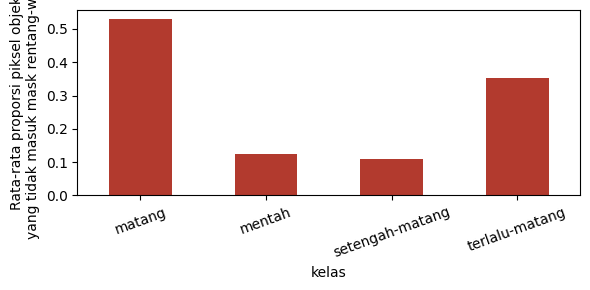

In [14]:
# --- 4b. Apakah mask rentang-warna kehilangan piksel objek? (referensi: mask kebalikan latar) ---
def compare_masks(df_train, n_per_class=30):
    rng = np.random.RandomState(SEED); rows = []
    for c in CLASS_ORDER:
        sub = df_train[df_train.label == c]
        sub = sub.iloc[rng.permutation(len(sub))[:n_per_class]]
        for p in sub.path:
            bgr = read_bgr(p)
            mb = run_pipeline(bgr, "bg")["mask"] > 0
            mr = run_pipeline(bgr, "range")["mask"] > 0
            inter = (mb & mr).sum()
            rows.append(dict(kelas=c, path=p,
                             piksel_objek_hilang=1 - inter / max(mb.sum(), 1),
                             iou=inter / max((mb | mr).sum(), 1)))
    return pd.DataFrame(rows)

cmp_ = compare_masks(train_df)
summ = cmp_.groupby("kelas")[["piksel_objek_hilang", "iou"]].mean().reindex(CLASS_ORDER)
display(summ.round(3))
ax = summ.piksel_objek_hilang.plot.bar(color="#B23A2E", figsize=(6, 3))
ax.set_ylabel("Rata-rata proporsi piksel objek\nyang tidak masuk mask rentang-warna"); plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig(OUT_DIR/"figures/mask_range_vs_bg.png", dpi=130); plt.show()
# Catatan: mask kebalikan latar bukan ground truth. Validasi sebenarnya memakai mask manual (IoU/Dice) di minggu 3.

## 5. Ekstraksi fitur ke `features.csv`

In [15]:
def extract_features(out):
    hsv, blur, mask = out["hsv"], out["blur"], out["mask"] > 0
    n = int(mask.sum()); f = {"mask_ratio": n / mask.size}
    cols = [f"{a}_{c}" for c in "HSV" for a in ("mean", "std")] + [f"mean_{c}" for c in "RGB"] + [f"prop_{k}" for k in HSV_RANGES]
    if n < MIN_PIXELS:
        f.update({c: 0.0 for c in cols}); f["seg_ok"] = 0
        return f
    px = hsv[mask].astype(np.float32)
    rgb = blur[mask][:, ::-1].astype(np.float32)
    for i, c in enumerate("HSV"):
        f[f"mean_{c}"] = float(px[:, i].mean()); f[f"std_{c}"] = float(px[:, i].std())
    for i, c in enumerate("RGB"):
        f[f"mean_{c}"] = float(rgb[:, i].mean())
    for k in HSV_RANGES:
        f[f"prop_{k}"] = float((in_range(hsv, k)[mask] > 0).mean())   # proporsi terhadap piksel mask
    f["seg_ok"] = int(SEG_OK_MIN <= f["mask_ratio"] <= SEG_OK_MAX)
    return f
# Catatan: rentang hue hijau-kuning-cokelat (5-85) tidak melewati batas 0/179, jadi mean H biasa masih wajar.
# Jika rentang diperluas ke merah, ganti dengan representasi melingkar (sin/cos).

recs = []
for i, r in df.iterrows():
    f = extract_features(run_pipeline(read_bgr(r.path)))
    f.update(nama_file=r.nama_file, split=r.split, label=r.label, path=r.path)
    recs.append(f)
    if (i + 1) % 500 == 0: print(f"{i+1}/{len(df)}")
feat = pd.DataFrame(recs)
feat.drop(columns="path").to_csv(OUT_DIR / "features.csv", index=False)
print(feat.shape, "| segmentasi gagal (seg_ok=0):", int((feat.seg_ok == 0).sum()))
display(feat.groupby(["split"]).size().to_frame("n"))
display(feat.drop(columns=["path", "nama_file", "split"]).groupby("label").mean().reindex(CLASS_ORDER).round(2))

500/1865
1000/1865
1500/1865
(1865, 18) | segmentasi gagal (seg_ok=0): 0


,n
split,
test,375
train,1443
val,47


,mask_ratio,mean_H,std_H,mean_S,std_S,mean_V,std_V,mean_R,mean_G,mean_B,prop_hijau,prop_kuning,prop_cokelat,seg_ok
label,,,,,,,,,,,,,,
matang,0.43,18.44,16.17,114.36,83.37,189.23,27.15,189.23,156.03,101.06,0.00,0.32,0.09,1.0
mentah,0.16,32.99,8.40,189.05,62.97,130.54,33.00,112.50,127.82,36.75,0.57,0.27,0.04,1.0
setengah-matang,0.18,28.76,6.78,189.04,68.48,168.22,31.03,159.47,161.22,45.21,0.09,0.76,0.04,1.0
terlalu-matang,0.22,21.71,18.09,147.57,66.41,161.31,35.32,161.31,124.21,66.62,0.00,0.28,0.40,1.0


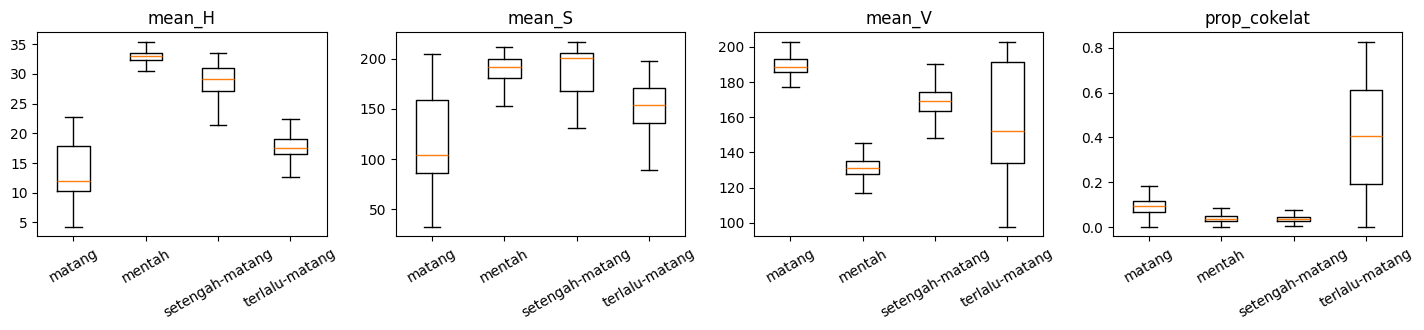

In [16]:
# Distribusi fitur per kelas (train)
show = ["mean_H", "mean_S", "mean_V", "prop_cokelat"]
fig, axes = plt.subplots(1, len(show), figsize=(3.6*len(show), 3.4))
ftr = feat[feat.split == "train"]
for ax, col in zip(axes, show):
    ax.boxplot([ftr[ftr.label == c][col] for c in CLASS_ORDER], labels=CLASS_ORDER, showfliers=False)
    ax.set_title(col); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(OUT_DIR/"figures/feature_dist.png", dpi=130); plt.show()

## 6. Hasil tiap tahap: contoh mudah dan sulit

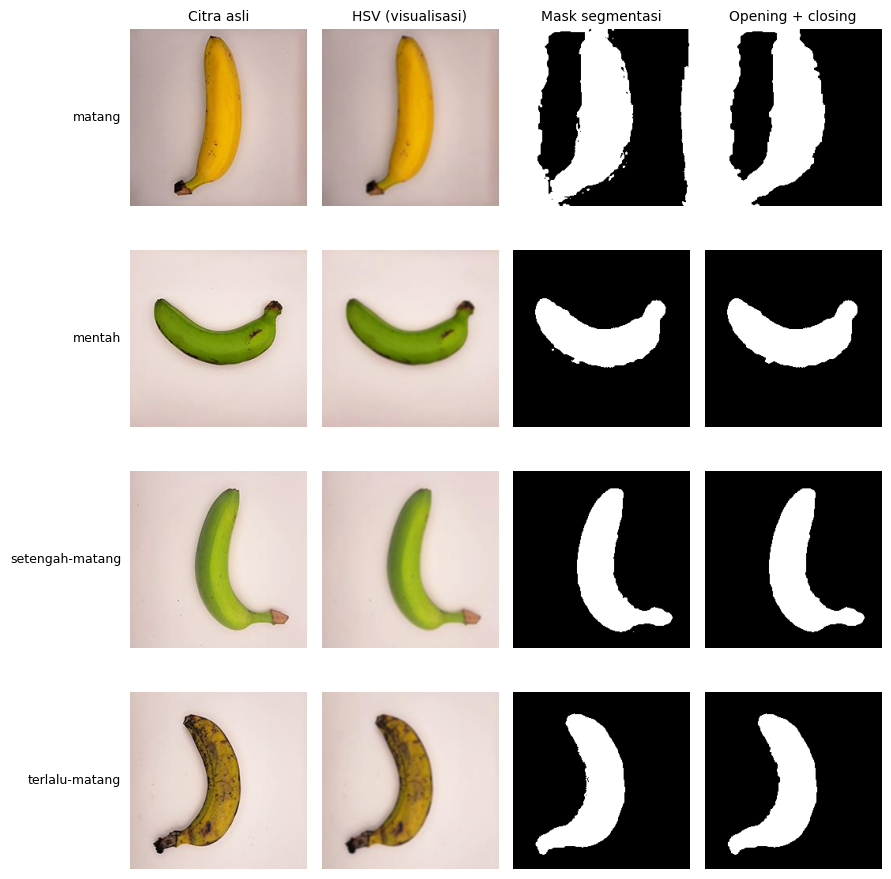

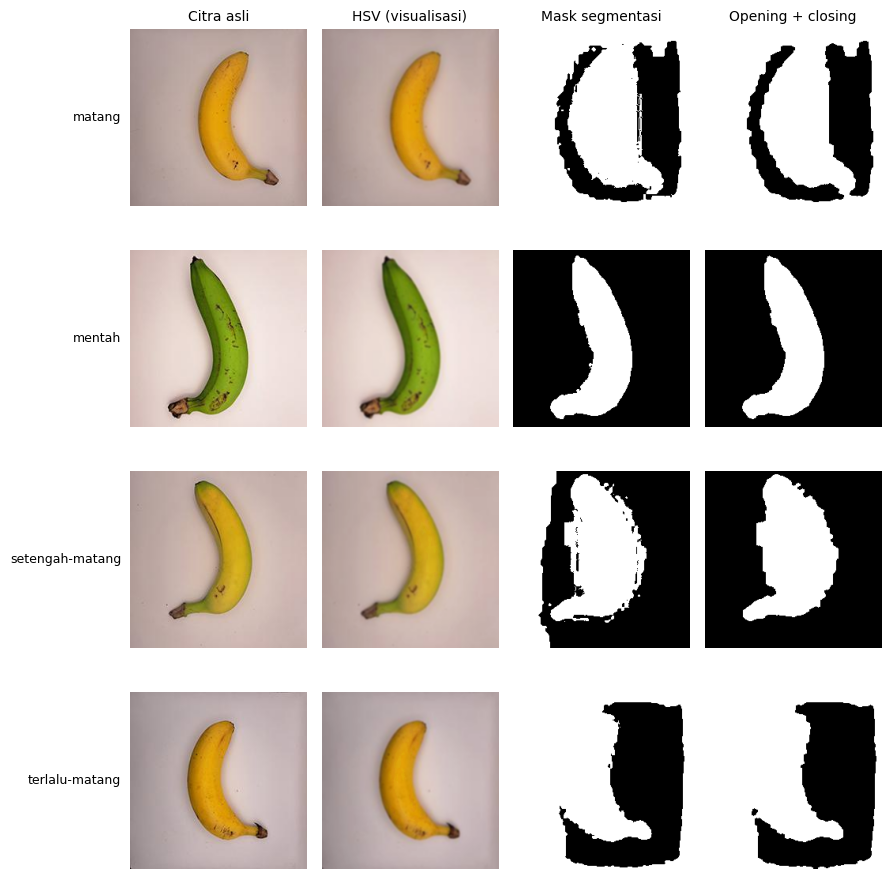

In [17]:
def show_steps(paths, titles, fname):
    cols = ["Citra asli", "HSV (visualisasi)", "Mask segmentasi", "Opening + closing"]
    fig, axes = plt.subplots(len(paths), 4, figsize=(9, 2.3*len(paths))); axes = np.atleast_2d(axes)
    for r, p in enumerate(paths):
        o = run_pipeline(read_bgr(p))
        imgs = [cv2.cvtColor(o["bgr"], cv2.COLOR_BGR2RGB), cv2.cvtColor(o["hsv"], cv2.COLOR_HSV2RGB), o["raw"], o["mask"]]
        for c in range(4):
            axes[r, c].imshow(imgs[c], cmap="gray" if c >= 2 else None); axes[r, c].axis("off")
            if r == 0: axes[r, c].set_title(cols[c], fontsize=10)
        axes[r, 0].text(-0.05, 0.5, titles[r], transform=axes[r, 0].transAxes, ha="right", va="center", fontsize=9)
    plt.tight_layout(); plt.savefig(OUT_DIR/f"figures/{fname}.png", dpi=130, bbox_inches="tight"); plt.show()

easy, hard = [], []
for c in CLASS_ORDER:
    s = feat[(feat.split == "train") & (feat.label == c)]
    med = s.mask_ratio.median()
    easy.append(s.iloc[(s.mask_ratio - med).abs().argmin()].path)    # mask paling "tipikal"
    hard.append(s.iloc[(s.mask_ratio - med).abs().argmax()].path)    # mask paling menyimpang
show_steps(easy, CLASS_ORDER, "pipeline_mudah")
show_steps(hard, CLASS_ORDER, "pipeline_sulit")

## 7. KNN awal (evaluasi di data validasi)
- Normalisasi (`StandardScaler`) dipelajari hanya dari data **train**.
- `k` dipilih di data **validasi** (macro-F1, lalu akurasi).
- Pembanding: tebakan kelas mayoritas, dan KNN pada mean RGB saja.

,model,akurasi,macro_f1
0,Baseline kelas mayoritas,0.128,0.057
1,KNN mean RGB (k=7),0.936,0.954
2,KNN fitur HSV (k=17),0.979,0.984


Data validasi: 47 citra | train: 1443 citra


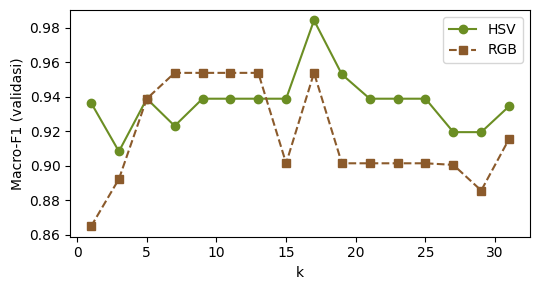

In [18]:
FEATS_HSV = ["mean_H", "std_H", "mean_S", "std_S", "mean_V", "std_V", "prop_hijau", "prop_kuning", "prop_cokelat"]
FEATS_RGB = ["mean_R", "mean_G", "mean_B"]
tr_, va_ = feat[feat.split == "train"], feat[feat.split == "val"]

# Tulis target keberhasilan SEBELUM melihat hasil (mis. 0.80), lalu jangan diubah.
TARGET_MACRO_F1 = None

def tune_knn(cols):
    sc = StandardScaler().fit(tr_[cols])
    Xtr, Xva = sc.transform(tr_[cols]), sc.transform(va_[cols])
    res = []
    for k in range(1, min(32, len(tr_)), 2):
        p = KNeighborsClassifier(n_neighbors=k).fit(Xtr, tr_.label).predict(Xva)
        res.append((k, accuracy_score(va_.label, p), f1_score(va_.label, p, average="macro")))
    res = pd.DataFrame(res, columns=["k", "acc", "macro_f1"])
    best = res.sort_values(["macro_f1", "acc", "k"], ascending=[False, False, True]).iloc[0]
    k = int(best.k)
    pred = KNeighborsClassifier(n_neighbors=k).fit(Xtr, tr_.label).predict(Xva)
    return res, k, pred

res_hsv, k_hsv, pred_hsv = tune_knn(FEATS_HSV)
res_rgb, k_rgb, pred_rgb = tune_knn(FEATS_RGB)
pred_maj = DummyClassifier(strategy="most_frequent").fit(tr_[FEATS_HSV], tr_.label).predict(va_[FEATS_HSV])

def row(name, p):
    return dict(model=name, akurasi=accuracy_score(va_.label, p), macro_f1=f1_score(va_.label, p, average="macro"))
table = pd.DataFrame([row("Baseline kelas mayoritas", pred_maj),
                      row(f"KNN mean RGB (k={k_rgb})", pred_rgb),
                      row(f"KNN fitur HSV (k={k_hsv})", pred_hsv)])
display(table.round(3)); table.to_csv(OUT_DIR / "knn_val_results.csv", index=False)
print(f"Data validasi: {len(va_)} citra | train: {len(tr_)} citra")
if TARGET_MACRO_F1 is not None:
    print("Target macro-F1:", TARGET_MACRO_F1, "| tercapai:", bool(table.macro_f1.iloc[-1] >= TARGET_MACRO_F1))

plt.figure(figsize=(5.5, 3))
plt.plot(res_hsv.k, res_hsv.macro_f1, "o-", color="#6B8E23", label="HSV"); plt.plot(res_rgb.k, res_rgb.macro_f1, "s--", color="#8B5A2B", label="RGB")
plt.xlabel("k"); plt.ylabel("Macro-F1 (validasi)"); plt.legend(); plt.tight_layout()
plt.savefig(OUT_DIR/"figures/knn_k_curve.png", dpi=130); plt.show()

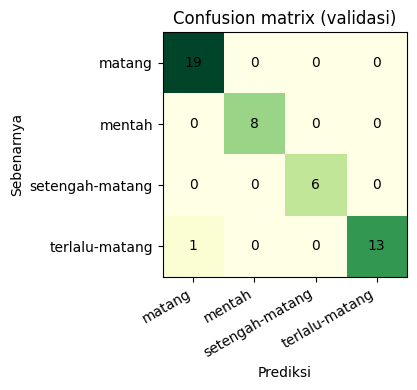

                 precision    recall  f1-score   support

         matang       0.95      1.00      0.97        19
         mentah       1.00      1.00      1.00         8
setengah-matang       1.00      1.00      1.00         6
 terlalu-matang       1.00      0.93      0.96        14

       accuracy                           0.98        47
      macro avg       0.99      0.98      0.98        47
   weighted avg       0.98      0.98      0.98        47

Analisis ordinal dilewati: atur CLASS_ORDER di bagian 0.
Citra validasi dengan seg_ok=0: 0


In [19]:
# Confusion matrix + laporan per kelas (validasi)
cm = confusion_matrix(va_.label, pred_hsv, labels=CLASS_ORDER)
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap="YlGn")
ax.set_xticks(range(len(CLASS_ORDER))); ax.set_xticklabels(CLASS_ORDER, rotation=30, ha="right")
ax.set_yticks(range(len(CLASS_ORDER))); ax.set_yticklabels(CLASS_ORDER)
for i in range(len(CLASS_ORDER)):
    for j in range(len(CLASS_ORDER)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="black")
ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya"); ax.set_title("Confusion matrix (validasi)")
plt.tight_layout(); plt.savefig(OUT_DIR/"figures/confusion_val.png", dpi=130); plt.show()
print(classification_report(va_.label, pred_hsv, labels=CLASS_ORDER, zero_division=0))

# Analisis ordinal: kesalahan antar-kelas bertetangga vs jauh
if ORDINAL_OK:
    diff = np.abs(va_.label.map(RANK).values - pd.Series(pred_hsv).map(RANK).values)
    wrong = diff > 0
    print(f"Salah: {wrong.sum()} dari {len(diff)} | bertetangga: {(diff == 1).sum()} | berjarak >= 2 kelas: {(diff >= 2).sum()}")
else:
    print("Analisis ordinal dilewati: atur CLASS_ORDER di bagian 0.")

# Kinerja pada citra dengan segmentasi gagal
bad = va_.seg_ok.values == 0
print(f"Citra validasi dengan seg_ok=0: {int(bad.sum())}")

## 8. Evaluasi test (JALANKAN SEKALI, DI AKHIR PROYEK)
Setelah semua keputusan (rentang HSV, fitur, `k`, ablation) final, ubah `RUN_TEST_EVAL = True`.
Jika dijalankan berulang sambil mengubah pipeline, data test berubah fungsi menjadi data validasi dan hasilnya tidak lagi jujur.

In [20]:
RUN_TEST_EVAL = False

if RUN_TEST_EVAL:
    te_ = feat[feat.split == "test"]
    trva = feat[feat.split.isin(["train", "val"])]
    sc = StandardScaler().fit(trva[FEATS_HSV])
    clf = KNeighborsClassifier(n_neighbors=k_hsv).fit(sc.transform(trva[FEATS_HSV]), trva.label)
    p = clf.predict(sc.transform(te_[FEATS_HSV]))
    print("Akurasi test:", round(accuracy_score(te_.label, p), 4), "| macro-F1:", round(f1_score(te_.label, p, average="macro"), 4))
    print(classification_report(te_.label, p, labels=CLASS_ORDER, zero_division=0))
else:
    print("Evaluasi test dinonaktifkan (RUN_TEST_EVAL=False).")

Evaluasi test dinonaktifkan (RUN_TEST_EVAL=False).
